# Fire history for Eastern Suburb Banksia Shrubs

In [1]:
library(lubridate)
library(sf)
require(stringr)
library(dplyr)
library(tibble)
library(ggplot2)


Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


Linking to GEOS 3.13.0, GDAL 3.8.5, PROJ 9.5.1; sf_use_s2() is TRUE

Loading required package: stringr


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:
here::i_am('NSW-Firehistory-ESBS.ipynb')

here() starts at /Users/z3529065/proyectos/CES/example-fire-NSW-workflow



In [3]:
gisdata_dir <- here::here('gisdata', 'NSW')

## Load GIS data

In [45]:
firehistory = read_sf(here::here(gisdata_dir , "NPWSFireHistory.shp")) |>
    st_transform(crs='EPSG:3577')

In [46]:
head(firehistory)

FireType,FireName,FireNo,Label,StartDate,EndDate,AreaHa,PerimeterM,d_FireType,geometry
<dbl>,<chr>,<chr>,<chr>,<date>,<date>,<dbl>,<dbl>,<chr>,<MULTIPOLYGON [m]>
2,NA,NA,1970-71 Prescribed Burn,-001-11-30,-001-11-30,299.98546,8615.637,Prescribed Burn,MULTIPOLYGON (((1943928 -36...
2,NA,70/161,1970-71 Prescribed Burn,-001-11-30,-001-11-30,309.02564,20657.634,Prescribed Burn,MULTIPOLYGON (((1820295 -36...
2,NA,NA,1970-71 Prescribed Burn,1970-07-01,-001-11-30,13.60000,1999.488,Prescribed Burn,MULTIPOLYGON (((2005159 -34...
2,NA,0,1971-72 Prescribed Burn,1971-07-01,-001-11-30,58.99437,5312.210,Prescribed Burn,MULTIPOLYGON (((1880863 -36...
2,NA,0,1971-72 Prescribed Burn,1971-07-01,-001-11-30,383.15515,20564.603,Prescribed Burn,MULTIPOLYGON (((1879013 -36...
2,NA,0,1971-72 Prescribed Burn,1971-07-01,-001-11-30,27.24194,3844.247,Prescribed Burn,MULTIPOLYGON (((1898440 -36...


In [47]:
table(is.na(firehistory$Label))
table(year(firehistory$StartDate) == -1,
      year(firehistory$EndDate) == -1)



FALSE 
37007 

       
        FALSE  TRUE
  FALSE 16656  5011
  TRUE    331 15009

In [48]:
firehistory <- firehistory |>
    mutate(
        source=case_when(
            year(StartDate)>-1 ~ "StartDate",
            year(EndDate)>-1 ~ "EndDate",
            TRUE ~ "Pseudodate"),
        bestdate=case_when(
            year(StartDate)>-1 ~ StartDate,
            year(EndDate)>-1 ~ EndDate,
            TRUE ~ as.Date(sprintf("%s/12/31",str_extract(Label,'[0-9]+')), format = "%Y/%m/%d"))
        )

In [49]:
head(firehistory)

FireType,FireName,FireNo,Label,StartDate,EndDate,AreaHa,PerimeterM,d_FireType,geometry,source,bestdate
<dbl>,<chr>,<chr>,<chr>,<date>,<date>,<dbl>,<dbl>,<chr>,<MULTIPOLYGON [m]>,<chr>,<date>
2,NA,NA,1970-71 Prescribed Burn,-001-11-30,-001-11-30,299.98546,8615.637,Prescribed Burn,MULTIPOLYGON (((1943928 -36...,Pseudodate,1970-12-31
2,NA,70/161,1970-71 Prescribed Burn,-001-11-30,-001-11-30,309.02564,20657.634,Prescribed Burn,MULTIPOLYGON (((1820295 -36...,Pseudodate,1970-12-31
2,NA,NA,1970-71 Prescribed Burn,1970-07-01,-001-11-30,13.60000,1999.488,Prescribed Burn,MULTIPOLYGON (((2005159 -34...,StartDate,1970-07-01
2,NA,0,1971-72 Prescribed Burn,1971-07-01,-001-11-30,58.99437,5312.210,Prescribed Burn,MULTIPOLYGON (((1880863 -36...,StartDate,1971-07-01
2,NA,0,1971-72 Prescribed Burn,1971-07-01,-001-11-30,383.15515,20564.603,Prescribed Burn,MULTIPOLYGON (((1879013 -36...,StartDate,1971-07-01
2,NA,0,1971-72 Prescribed Burn,1971-07-01,-001-11-30,27.24194,3844.247,Prescribed Burn,MULTIPOLYGON (((1898440 -36...,StartDate,1971-07-01


In [50]:
table(firehistory$source)


   EndDate Pseudodate  StartDate 
       331      15009      21667 

In [19]:
TECdist <- read_sf(here::here(gisdata_dir, "Threatened_ecological_communities_GreaterSydney_2024.shp"))

In [22]:
TECdist |> 
    st_drop_geometry() |>
    group_by(`POTENTIAL_`) |>
    summarise(count=n(),area=sum(`Shape_Area`))

POTENTIAL_,count,area
<chr>,<int>,<dbl>
TEC_ABW,29,1.605273e-04
TEC_BGHF,1832,7.728779e-04
TEC_BMBF,549,4.320955e-03
TEC_BMSCF,28,9.911068e-05
TEC_BMSw,1885,3.103050e-03
TEC_BSF,20,2.158479e-05
TEC_CPW,12412,2.141842e-02
TEC_CRCIF,1541,4.933882e-03
TEC_CSGW,815,3.736169e-03


This is the plan
- [x] select ESBS polygons
- [x] select random points inside polygons (1, 5, 10 per polygon)
- [ ] for each point use a random sampling date,
- [x] intersect points with firehistory
- [x] aggregate by points and calculate number of fires, earliests and latest fire year
- [x] histograms of these
- [ ] calculate intervals from sampling date to last fire and penultimate fire
- [ ] histograms of these

In [61]:
pts01 <- TECdist |> 
    filter(POTENTIAL_=="TEC_ESBS") |>
    st_zm(drop=TRUE) |>
    st_set_agr('constant') |>
    st_transform(crs='EPSG:3577') |> 
    st_point_on_surface() |> 
    rowid_to_column("pid")

In [62]:
set.seed(1984)
pts01$sampling_date <- sample(seq(as.Date('2015-01-01'), as.Date('2025-01-01'), by = "day"), nrow(pts01))

In [63]:
head(pts01)

pid,POTENTIAL_,NSW_LISTIN,SAII_STATU,SOURCE_POL,SOURCE_MAP,SOURCE_M_1,AREA_HA,RFS1050,VerDate,Shape_Leng,Shape_Area,geometry,sampling_date
<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<date>,<dbl>,<dbl>,<POINT [m]>,<date>
1,TEC_ESBS,Critically endangered,SAII,Sydney Metro v3 VIS 4489 (2016),S_HL04,Coastal Sandplain Heath,10.38341027,Yes,2024-10-31,0.038978672,1.015417e-05,POINT (1757977 -3847172),2021-01-24
2,TEC_ESBS,Critically endangered,SAII,Sydney Metro v3 VIS 4489 (2016),S_HL04,Coastal Sandplain Heath,14.39992132,Yes,2024-10-31,0.036498827,1.408203e-05,POINT (1757703 -3847067),2018-04-24
3,TEC_ESBS,Critically endangered,SAII,Sydney Metro v3 VIS 4489 (2016),S_HL03,Coastal Sand Mantle Heath,0.09723813,Yes,2024-10-31,0.001603722,9.504235e-08,POINT (1762642 -3842603),2023-12-25
4,TEC_ESBS,Critically endangered,SAII,Sydney Metro v3 VIS 4489 (2016),S_HL04,Coastal Sandplain Heath,0.28068184,Yes,2024-10-31,0.002506781,2.743262e-07,POINT (1762325 -3841912),2023-12-29
5,TEC_ESBS,Critically endangered,SAII,Sydney Metro v3 VIS 4489 (2016),S_HL03,Coastal Sand Mantle Heath,0.66732336,Yes,2024-10-31,0.003359462,6.522096e-07,POINT (1762187 -3841840),2020-10-26
6,TEC_ESBS,Critically endangered,SAII,Sydney Metro v3 VIS 4489 (2016),S_HL03,Coastal Sand Mantle Heath,1.79538230,Yes,2024-10-31,0.009494814,1.754878e-06,POINT (1762709 -3842821),2016-11-02


In [64]:

fh_ESBS_01 = st_join(pts01,firehistory,how='left') 

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


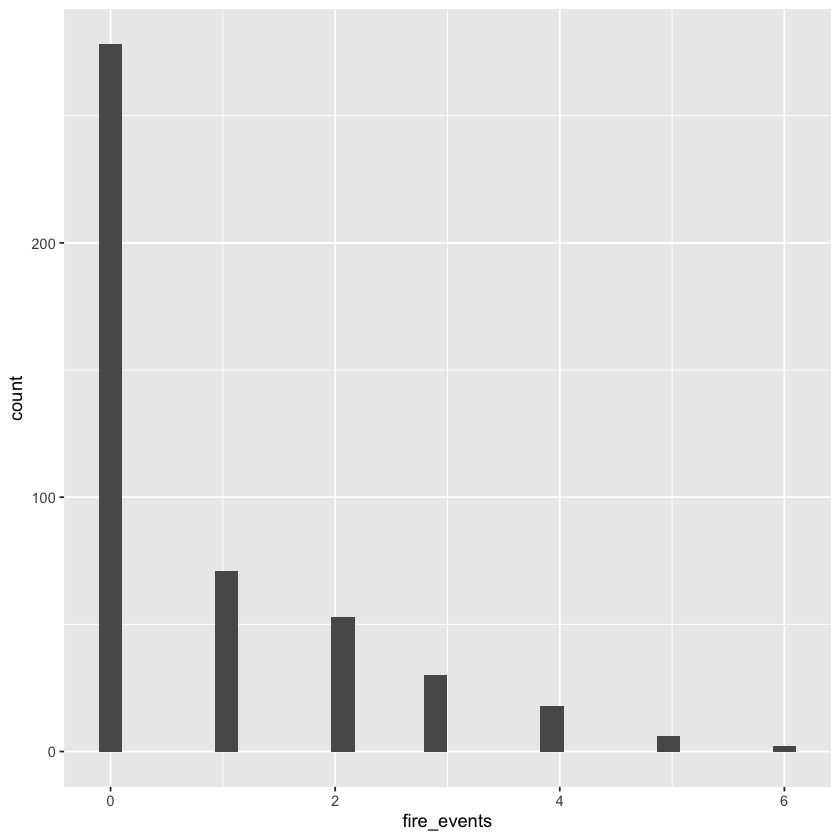

In [71]:
fh_ESBS_01 |>
    group_by(pid) |>
    summarise(fire_events = sum(!is.na(bestdate))) |>
    ggplot() + geom_histogram(aes(x=fire_events))

In [57]:
rownames(pts01)[1:2]

[1] "1" "2"

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
“Removed 278 rows containing non-finite outside the scale range (`stat_bin()`).”


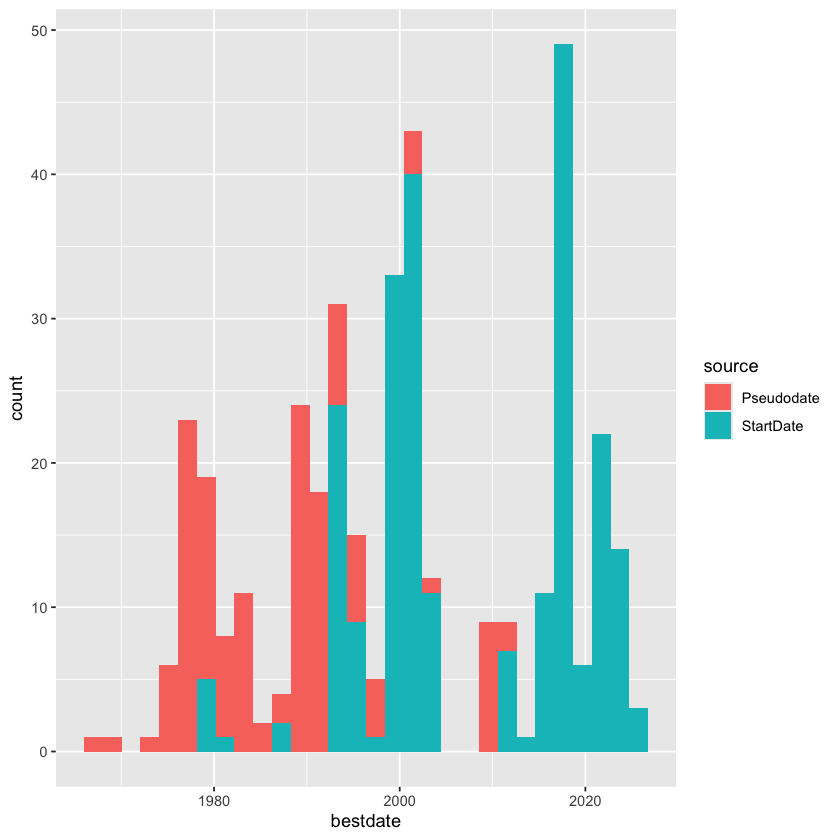

In [73]:
fh_ESBS_01 |>
    ggplot() + geom_histogram(aes(x=bestdate, fill=source))

In [114]:
years(duration(0))

[1] "0S"

In [139]:
fh_ESBS_01 |>
    st_drop_geometry() |>
    select(pid,Label,StartDate,EndDate,
           sampling_date,bestdate) |>
    mutate(inter=sampling_date-bestdate) |>
    mutate(interval = case_when(
        is.na(inter) ~ duration(0),
        sign(inter) == -1 ~ duration(0),
        TRUE ~ inter)) |>
    group_by(pid) |>
    arrange(pid,desc(bestdate)) |>
    slice(1:2) |> 
    mutate(repeated=duplicated(pid)) |>
    mutate(case_when(
        repeated & interval>0 ~ "penultimate",
        interval>0 ~ "last",
        TRUE ~ "no fire")) |>
    ungroup() |>
    slice_head(n=5)

pid,Label,StartDate,EndDate,sampling_date,bestdate,inter,interval,repeated,case_when(...)
<int>,<chr>,<date>,<date>,<date>,<date>,<drtn>,<Duration>,<lgl>,<chr>
1,2017-18 Wildfire,2017-09-03,2017-09-10,2021-01-24,2017-09-03,1239 days,107049600s (~3.39 years),FALSE,last
1,2000-01 Wildfire,2000-10-03,-001-11-30,2021-01-24,2000-10-03,7418 days,640915200s (~20.31 years),TRUE,penultimate
2,2000-01 Wildfire,2000-10-03,-001-11-30,2018-04-24,2000-10-03,6412 days,553996800s (~17.56 years),FALSE,last
3,NA,NA,NA,2023-12-25,NA,NA days,0s,FALSE,no fire
4,NA,NA,NA,2023-12-29,NA,NA days,0s,FALSE,no fire


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


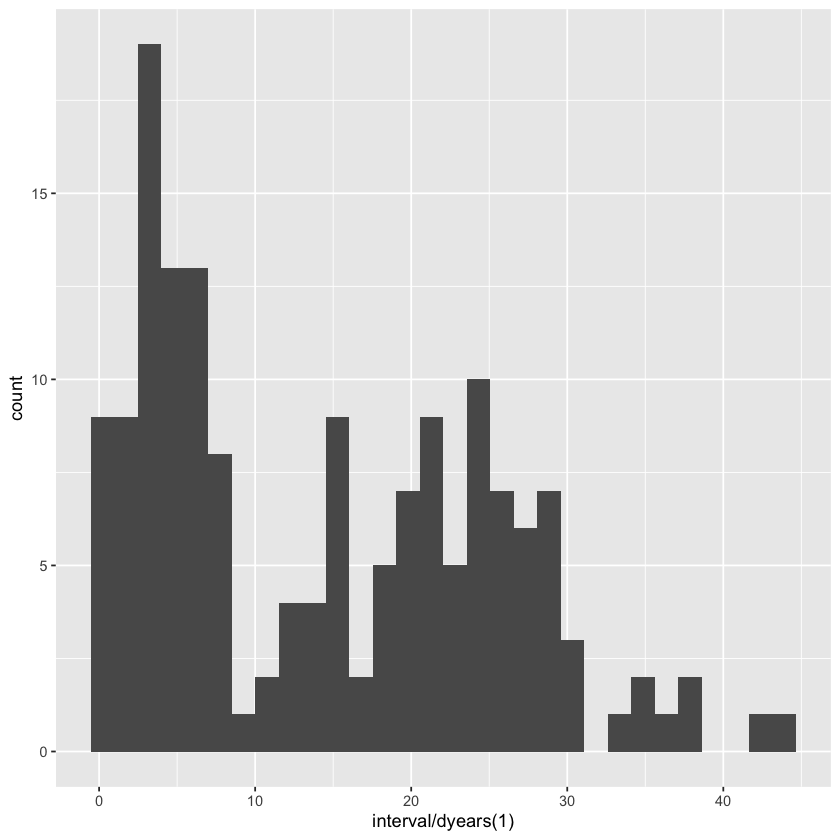

In [125]:
fh_ESBS_01 |>
    st_drop_geometry() |>
    mutate(interval=sampling_date-bestdate) |>
    filter(interval>0) |>
    arrange(pid,desc(bestdate)) |>
    group_by(pid)  |>
    slice(1) |> 
    ggplot() +
    geom_histogram(aes(x=interval/dyears(1)))

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


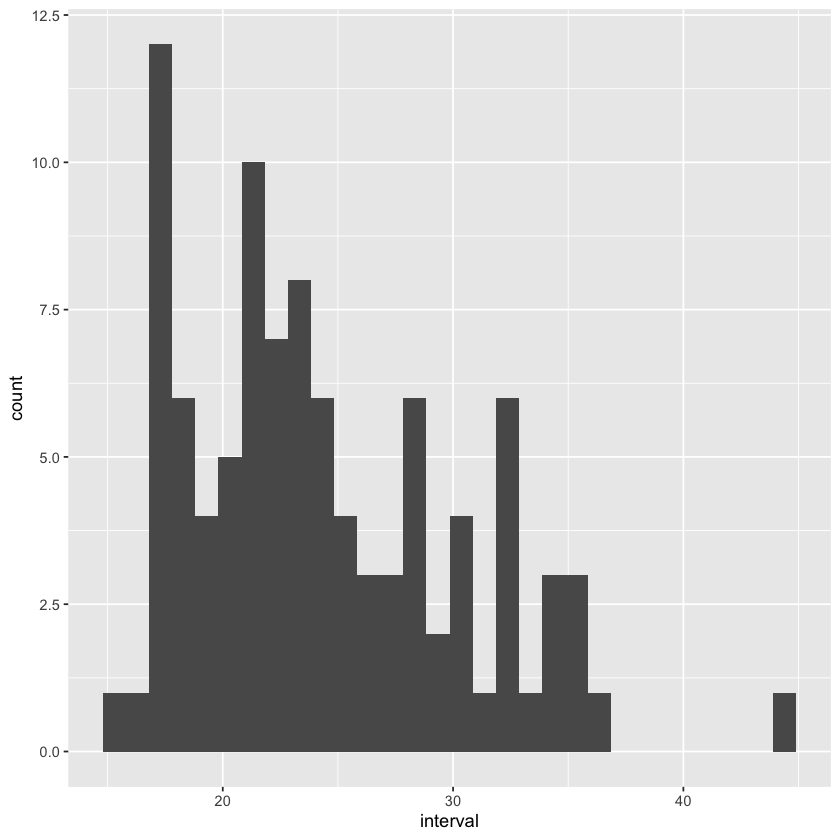

In [124]:
fh_ESBS_01 |>
    st_drop_geometry() |>
    mutate(inter=sampling_date-bestdate) |>
    filter(inter>0) |>
    mutate(interval=inter/dyears(1)) |>
    arrange(pid,desc(bestdate)) |>
    group_by(pid)  |>
    slice(2) |> 
    ggplot() +
    geom_histogram(aes(x=interval))

In [130]:
?cume_dist


percent_rank {dplyr},R Documentation
x,"A vector to rank By default, the smallest values will get the smallest ranks. Use desc() to reverse the direction so the largest values get the smallest ranks. Missing values will be given rank NA. Use coalesce(x, Inf) or coalesce(x, -Inf) if you want to treat them as the largest or smallest values respectively. To rank by multiple columns at once, supply a data frame."
